In [48]:
from joblib import load
import sys
import seaborn as sns
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
from adjustText import adjust_text
sys.path.append('/home/jhu/jkim789/scratch_aphill27/software/Pooch/pofo_tools/src/')
import pofo_tools
from pofo_tools.utils import *

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

figureDir = "/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/prediction/"
import os 
os.makedirs(figureDir, exist_ok=True)

In [49]:
# autosome models
mode = "models_using_only_knowniDMR_CpGs"
mode = "models_using_80_cpg_outside_knowniDMR_padding100kbp"
mode = "models_using_80_cpg_outside_knowniDMR_fixed"
mode = "models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed"
mode = "models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed"

# chrX models
mode = "models_selection_using_fdr_balance_X_n46_xist_slope_adjust"

In [50]:
files = glob.glob(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.{mode}/*predict.out")
df = pd.DataFrame()
for file in files:
    chr = file.split("/")[-1].split(".")[0]
    temp_df = pd.read_csv(file, sep="\t", header = 0)
    temp_df["chr"] = chr
    df = pd.concat([df, temp_df], ignore_index=True)
    
df['chr'] = pd.Categorical(df['chr'], categories=[f"chr{i}" for i in range(1, 23)], ordered=True)
df.head(2)

,Sample,LeftOpHapLabel,RightOpHapLabel,LeftHapPredictedOrigin,RightHapPredictedOrigin,PredictProb_Maternal-Paternal,PredictProb_Paternal-Maternal,PredictionCorrect,chr
0,HG002,Maternal,Paternal,Maternal,Paternal,0.999988,0.000012,Unknown,chr8
1,HG00408,Maternal,Paternal,Maternal,Paternal,0.999955,0.000045,Unknown,chr8


In [51]:
for chr in df['chr'].unique():
    if chr == "chrX" :
        testset = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X/chrX.balance.test.txt", sep ='\t', header = None)[0].to_list()
        trainingset = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X/chrX.balance.training.txt", sep ='\t', header = None)[0].to_list()
    else :
        testset = pd.read_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/model_validation/model_juhyun/test_data/testSet.samplelist", sep ='\t', header = None)[0].to_list()
        trainingset = pd.read_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/model_validation/model_juhyun/test_data/trainSet.samplelist", sep ='\t', header = None)[0].to_list()

    df.loc[df['chr'] == chr, 'Set'] = df.loc[df['chr'] == chr, 'Sample'].apply(lambda x: 'Test' if x in testset else ('Train' if x in trainingset else 'Unknown'))

In [61]:
# swap samples
df['Prob'] = df['PredictProb_Maternal-Paternal']
swap_samples = ['HG02451','HG02717','HG03579']
sample_col = 'sample' if 'sample' in df.columns else 'Sample'
for sample in swap_samples:
    mask = df[sample_col] == sample
    df.loc[mask, 'Prob'] = df.loc[mask, 'PredictProb_Paternal-Maternal']
df

df.loc[df['Sample'].isin(swap_samples)]

,Sample,LeftOpHapLabel,RightOpHapLabel,LeftHapPredictedOrigin,RightHapPredictedOrigin,PredictProb_Maternal-Paternal,PredictProb_Paternal-Maternal,PredictionCorrect,chr,Set,Prob
72,HG02451,Maternal,Paternal,Paternal,Maternal,0.000076,0.999924,Unknown,chr8,Test,0.999924
86,HG02717,Maternal,Paternal,Paternal,Maternal,0.000042,0.999958,Unknown,chr8,Test,0.999958
103,HG03579,Maternal,Paternal,Paternal,Maternal,0.000032,0.999968,Unknown,chr8,Test,0.999968
195,HG02451,Maternal,Paternal,Paternal,Maternal,0.365925,0.634075,Unknown,chr12,Test,0.634075
209,HG02717,Maternal,Paternal,Paternal,Maternal,0.000159,0.999841,Unknown,chr12,Test,0.999841
...,...,...,...,...,...,...,...,...,...,...,...
2545,HG02717,Maternal,Paternal,Paternal,Maternal,0.000171,0.999829,Unknown,chr9,Test,0.999829
2562,HG03579,Maternal,Paternal,Paternal,Maternal,0.000241,0.999759,Unknown,chr9,Test,0.999759
2654,HG02451,Maternal,Paternal,Paternal,Maternal,0.000023,0.999977,Unknown,chr18,Test,0.999977
2668,HG02717,Maternal,Paternal,Paternal,Maternal,0.000003,0.999997,Unknown,chr18,Test,0.999997


In [62]:
if mode == "models_selection_using_fdr_balance_X_n46_xist_slope_adjust":
    # This one already have corrected value for swap samples
    df_chrX = pd.read_csv(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.{mode}//chrX.slope_adjusted.test.predictions.fixed_swap_sample.tsv", sep = '\t', header = 0)
    df_chrX = df_chrX.loc[df_chrX['y_true'] == 1]
    df_chrX['chr'] = 'chrX'
    df_chrX['Set'] = "Test"
    df_chrX = df_chrX[['chr','Sample','p_right_paternal']]
    df_chrX.columns = ['chr','Sample','Prob']
    df_merge = pd.concat([df.loc[df['Set'] == "Test"], df_chrX])
else :
    df_merge =df.loc[df['Set'] == "Test"]

df_merge['chr'] = pd.Categorical(df_merge['chr'], categories=[f"chr{i}" for i in range(1, 23)] + ["chrX"], ordered=True)
df_merge.head(2)

,Sample,LeftOpHapLabel,RightOpHapLabel,LeftHapPredictedOrigin,RightHapPredictedOrigin,PredictProb_Maternal-Paternal,PredictProb_Paternal-Maternal,PredictionCorrect,chr,Set,Prob
0,HG002,Maternal,Paternal,Maternal,Paternal,0.999988,0.000012,Unknown,chr8,Test,0.999988
1,HG00408,Maternal,Paternal,Maternal,Paternal,0.999955,0.000045,Unknown,chr8,Test,0.999955


In [63]:
df_merge.groupby("chr").size()

chr
chr1     43
chr2     43
chr3     43
chr4     43
chr5     43
chr6     43
chr7     43
chr8     43
chr9     43
chr10    43
chr11    43
chr12    42
chr13    43
chr14    43
chr15    43
chr16    43
chr17    43
chr18    43
chr19    43
chr20    43
chr21    43
chr22    43
chrX     13
dtype: int64

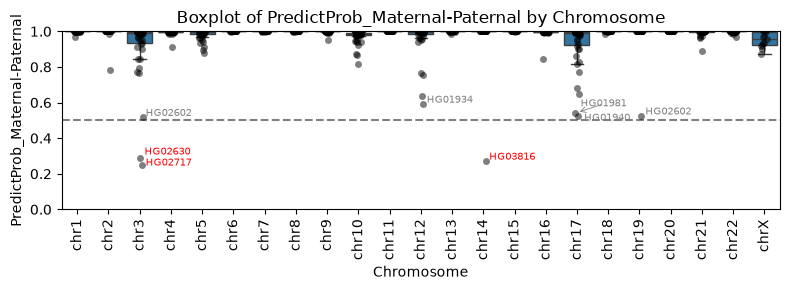

In [64]:
test_df = df_merge.copy()
chr_order = [f"chr{i}" for i in range(1, 23)] + ['chrX']
chr_to_x = {c: i for i, c in enumerate(chr_order)}
# remove Y
test_df = test_df[test_df['chr'] != 'chrY']

fig, ax = plt.subplots(figsize=(8, 3))
# fig, ax = plt.subplots(figsize=(20, 3))
sns.boxplot(x="chr", y="Prob", data=test_df, showfliers=False, ax=ax)
sns.stripplot(x="chr", y="Prob", data=test_df, color='black', alpha=0.5, ax=ax)
# sns.violinplot(x="chr", y="Prob", data=test_df,ax=ax)
plt.xticks(rotation=90)
plt.title("Boxplot of PredictProb_Maternal-Paternal by Chromosome")
plt.xlabel("Chromosome")
plt.ylim(0, 1)
plt.ylabel("PredictProb_Maternal-Paternal")
plt.axhline(0.5, color='gray', linestyle='--', zorder=-1)

label = True

# Label low-probability samples and repel text to avoid overlap
if label:
    moderate = test_df[test_df['Prob'].between(0.5, 0.6)]
    texts = []
    for _, row in moderate.iterrows():
        x = chr_to_x.get(row['chr'], 0)
        texts.append(
            ax.text(x, row['Prob'], row['Sample'], fontsize=7, color='grey')
        )

    low = test_df[test_df['Prob'] <= 0.5]
    for _, row in low.iterrows():
        x = chr_to_x.get(row['chr'], 0)
        texts.append(
            ax.text(x, row['Prob'], row['Sample'], fontsize=7, color='red')
        )

    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(arrowstyle='->', color='gray', lw=0.6),
        expand_points=(1.2, 1.4),
        expand_text=(1.2, 1.4),
        force_text=(0.2, 0.3),
    )

plt.tight_layout()
# plt.savefig(f"{figureDir}/violinplot_PredictProb_Maternal-Paternal_by_chr_{mode}.pdf")
plt.savefig(f"{figureDir}/boxplot_PredictProb_Maternal-Paternal_by_chr_balanceX.{mode}.pdf")
plt.show()

In [65]:
from sklearn.metrics import brier_score_loss
import pandas as pd
import numpy as np

brier_df = (
    df_merge.assign(
        Prob=pd.to_numeric(df["Prob"], errors="coerce")
    )
    .dropna(subset=["Prob"])
    .groupby("chr")
    .agg(
        n=("Prob", "size"),
        brier_score=("Prob", lambda x: brier_score_loss(
            np.ones(len(x)), x
        ))
    )
    .reset_index()
)

brier_df

,chr,n,brier_score
0,chr1,43,2.837245e-05
1,chr2,43,1.115366e-03
2,chr3,43,3.552631e-02
3,chr4,43,2.014004e-04
4,chr5,43,1.122595e-03
5,chr6,43,3.494542e-08
6,chr7,43,2.621360e-07
7,chr8,43,7.899240e-08
8,chr9,43,5.315261e-05
9,chr10,43,2.245548e-03


In [36]:
print(f"{figureDir}/boxplot_PredictProb_Maternal-Paternal_by_chr_balanceX.pdf")

/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/prediction//boxplot_PredictProb_Maternal-Paternal_by_chr_balanceX.pdf


## Ethnity check

In [91]:
file= "/home/jhu/jkim789/projects_aphill27/projects/pooch//for-juhyun/hprc-samples-metadata/hprc-sequence-production.extra.tsv"

hprc_meta = pd.read_csv(file, sep="\t", header = 0)
hprc_meta['Set'] = ""
hprc_meta.loc[hprc_meta['ChildID'].isin(testset), "Set"] = "Test"
hprc_meta.loc[hprc_meta['ChildID'].isin(trainingset), "Set"] = "Train"
hprc_meta = hprc_meta.loc[hprc_meta['Set'] != ""]
hprc_meta.head(2)

,ChildID,N,Sex,Subpopulation,Superpopulation,Production Year,Set
0,HG02145,BB20,male,ACB,AFR,?,Test
1,HG02109,BB18,female,ACB,AFR,?,Test


In [92]:
hprc_meta.loc[hprc_meta['Subpopulation'] == "?"]

,ChildID,N,Sex,Subpopulation,Superpopulation,Production Year,Set
3,HG002,3140,male,?,?,?,Test
4,HG005,3150,male,?,?,?,Train


In [93]:
hprc_meta.head(2)

,ChildID,N,Sex,Subpopulation,Superpopulation,Production Year,Set
0,HG02145,BB20,male,ACB,AFR,?,Test
1,HG02109,BB18,female,ACB,AFR,?,Test


In [94]:
df_eth_df.head(2)

,Superpopulation,Set,count
0,AFR,Test,12
1,AFR,Train,19


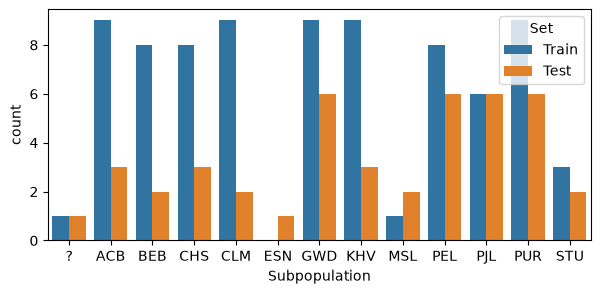

In [95]:
y = "Subpopulation"

df_eth_df = hprc_meta.groupby([y,"Set"]).size().reset_index(name='count')
df_eth_df['Set'] = pd.Categorical(df_eth_df['Set'] , categories = ["Train", "Test"], ordered = True)

plt.figure(figsize = (7,3))
sns.barplot(df_eth_df, hue = "Set", x = y, y = "count")

plt.savefig(f"{figureDir}/dataset_by_{y}.pdf")

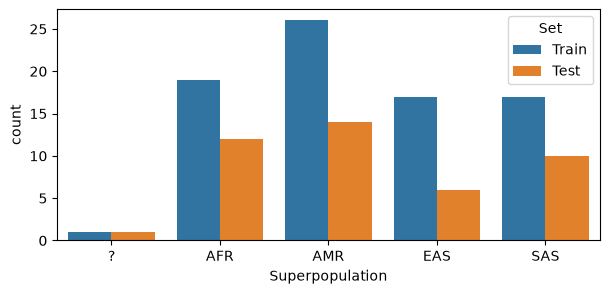

In [96]:
y = "Superpopulation"

df_eth_df = hprc_meta.groupby([y,"Set"]).size().reset_index(name='count')
df_eth_df['Set'] = pd.Categorical(df_eth_df['Set'] , categories = ["Train", "Test"], ordered = True)

plt.figure(figsize = (7,3))
sns.barplot(df_eth_df, hue = "Set", x = y, y = "count")

plt.savefig(f"{figureDir}/dataset_by_{y}.pdf")

In [97]:
hprc_meta.loc[hprc_meta['ChildID']=="HG002", "Subpopulation"] = 'AJ'
hprc_meta.loc[hprc_meta['ChildID']=="HG002", "Superpopulation"] = 'EUR'

hprc_meta.loc[hprc_meta['ChildID']=="HG005", "Subpopulation"] = 'CHS'
hprc_meta.loc[hprc_meta['ChildID']=="HG005", "Superpopulation"] = 'EAS'

In [98]:
df_eth = pd.merge(df_merge, hprc_meta, left_on = "Sample", right_on="ChildID", how="left")
df_eth

,Sample,LeftOpHapLabel,RightOpHapLabel,LeftHapPredictedOrigin,RightHapPredictedOrigin,PredictProb_Maternal-Paternal,PredictProb_Paternal-Maternal,PredictionCorrect,chr,Set_x,Prob,ChildID,N,Sex,Subpopulation,Superpopulation,Production Year,Set_y
0,HG002,Maternal,Paternal,Maternal,Paternal,0.999988,0.000012,Unknown,chr8,Test,0.999988,HG002,3140,male,AJ,EUR,?,Test
1,HG00408,Maternal,Paternal,Maternal,Paternal,0.999955,0.000045,Unknown,chr8,Test,0.999955,HG00408,SH002,female,CHS,EAS,YR3,Test
2,HG00558,Maternal,Paternal,Maternal,Paternal,0.999933,0.000067,Unknown,chr8,Test,0.999933,HG00558,SH045,female,CHS,EAS,YR3,Test
3,HG00597,Maternal,Paternal,Maternal,Paternal,0.999933,0.000067,Unknown,chr8,Test,0.999933,HG00597,SH058,female,CHS,EAS,YR3,Test
4,HG00733,Maternal,Paternal,Maternal,Paternal,0.999908,0.000092,Unknown,chr8,Test,0.999908,HG00733,PR05,female,PUR,AMR,?,Test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
953,HG02451,NaN,NaN,NaN,NaN,NaN,NaN,NaN,chrX,NaN,0.916848,HG02451,BB46,female,ACB,AFR,YR3,Test
954,HG02523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,chrX,NaN,0.999855,HG02523,VN090,female,KHV,EAS,YR2,Train
955,HG02615,NaN,NaN,NaN,NaN,NaN,NaN,NaN,chrX,NaN,0.974021,HG02615,GB29,female,GWD,AFR,YR2,Train
956,HG02723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,chrX,NaN,0.900085,HG02723,GB52,female,GWD,AFR,?,Test


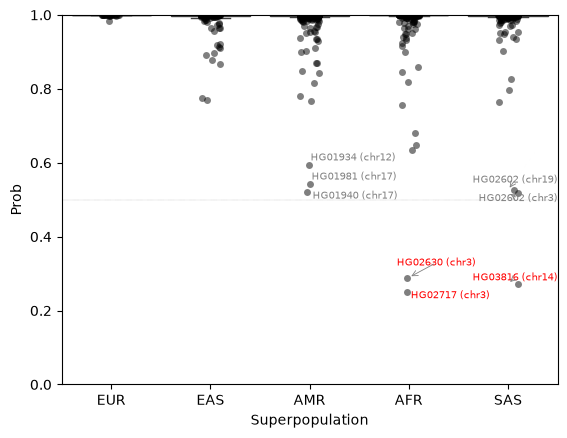

In [99]:
x = "Superpopulation"

# df_eth_test = df_eth.loc[df_eth['Set']=="Test"].copy()
df_eth_test = df_eth.copy()
x_order = df_eth_test[x].unique()
x_to_x = {c: i for i, c in enumerate(x_order)}
sns.boxplot(data=df_eth_test, x=x, y="Prob", order=x_order, showfliers=False)
sns.stripplot(data=df_eth_test, x=x, y="Prob", color='black', alpha=0.5)
plt.ylim(0,1)


# label 
# Label low-probability samples and repel text to avoid overlap
moderate = df_eth_test[df_eth_test['Prob'].between(0.5, 0.6)]
texts = []
for _, row in moderate.iterrows():
    x_val = x_to_x.get(row[x], 0)
    texts.append(
        plt.text(x_val, row['Prob'], f"{row['Sample']} ({row['chr']})", fontsize=7, color='grey')
    )

low = df_eth_test[df_eth_test['Prob'] <= 0.5]
for _, row in low.iterrows():
    x_val = x_to_x.get(row[x], 0)
    texts.append(
        plt.text(x_val, row['Prob'], f"{row['Sample']} ({row['chr']})", fontsize=7, color='red')
    )

adjust_text(
    texts,
    ax=plt.gca(),
    arrowprops=dict(arrowstyle='->', color='gray', lw=0.6),
    expand_points=(1.2, 1.4),
    expand_text=(1.2, 1.4),
    force_text=(0.2, 0.3),
)
plt.axhline(0.5, color='grey', linestyle=':', linewidth=0.3)
plt.savefig(f"{figureDir}/boxplot_by_ethnicity_{x}.pdf")

## Summary

In [101]:
# results = glob.glob(f"/data/Phillippy/projects/pooch_snakemake/pooch_data/07.models_using_only_knowniDMR_CpGs/elasticnet_select*")
# mode = "models_selection_using_fdr_balance_X_n46_xist_slope_adjust"
# mode = "models_selection_using_fdr"
# mode = "models_using_only_knowniDMR_CpGs"
#mode = "models_using_80_cpg_outside_knowniDMR_fixed"
#mode = "models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed"
#mode = "models_using_80_cpg_outside_knowniDMR_padding100kbp"
#mode = "models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed"


results = glob.glob(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.{mode}/elasticnet_select*")

summaryA = pd.DataFrame()
for result in results:
    chr = result.split("/")[-1].split(".")[0].split("_")[-1]
    temp_df = pd.read_csv(result, sep=",", header = 0)
    temp_df["chr"] = chr
    summaryA = pd.concat([summaryA, temp_df], ignore_index=True)
summaryA['mode'] = mode
summaryA.head(2)


,original_CpG,total_CpG,selected_CpG,cv_auc,best_c,best_l1_ratio,Test_Accuracy,Test_Balanced_Accuracy,Test_Brier_Score,chr,mode
0,1213961,21753,1473,0.9983,10,0.25,1.000000,1.000000,0.010132,chr12,models_selection_using_fdr_balance_X_n46_xist_...
1,800514,16265,2210,1.0000,100,0.25,0.976744,0.976744,0.012307,chr14,models_selection_using_fdr_balance_X_n46_xist_...


In [105]:
if mode == 'models_selection_using_fdr_balance_X_n46_xist_slope_adjust':
    summaryB = pd.read_csv(f"/path/to/project/pooch/pooch_data/07.{mode}/chrX.slope_adjusted.metrics.csv",  sep = ',', header = 0)
    summaryB['mode'] = mode
    summaryB['chr'] = "chrX"
    summaryB[['original_CpG','total_CpG','selected_CpG','chr','mode', 'cv_auc', 'Test_Balanced_Accuracy']]
    summaryA = pd.concat([summaryA, summaryB])

In [106]:
summaryA['chr'] = pd.Categorical(summaryA['chr'], categories=[f"chr{i}" for i in range(1, 23)] + ['chrX'], ordered=True)

In [107]:
len(set(summaryA['chr']))

23

/tmp/ipykernel_1615395/342462958.py:13: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


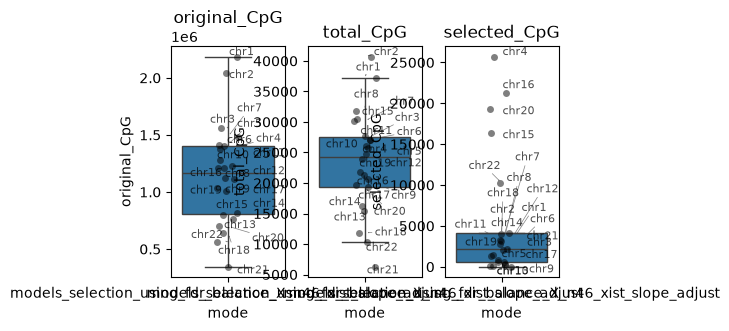

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(5, 3), sharex=True, sharey=False)

plot_df = summaryA.loc[summaryA['chr'] != "chrX"]
for ax, col in zip(axes, ['original_CpG', 'total_CpG', 'selected_CpG']):
    sns.boxplot(plot_df, x='mode', y=col, showfliers=False, ax=ax)
    sns.stripplot(plot_df, x='mode', y=col, color='black', alpha=0.5, ax=ax)

    # add text labels for every dot, repelled to avoid overlap
    texts = [ax.text(x=0, y=row[col], s=row['chr'], fontsize=8, color='black', alpha=0.7) for _, row in plot_df.iterrows()]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='->', color='gray', lw=0.5))
    ax.set_title(col)

plt.tight_layout()
plt.savefig(f"{figureDir}/number_of_cpGs_for_{mode}.pdf")
plt.show()

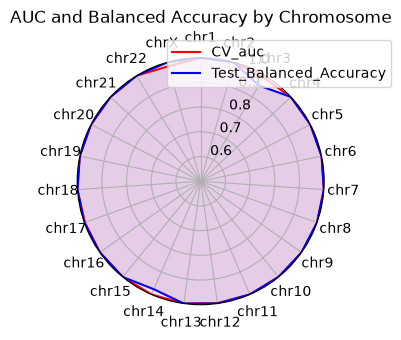

In [109]:
# circle radar plot using av_auc (red) and Test_Balanced_Accuracy (blue)
# note: summaryA has no 'av_auc' column, using 'cv_auc' as the average AUC metric


radar_df = summaryA[['chr', 'cv_auc', 'Test_Balanced_Accuracy']].dropna().copy()
radar_df['chr'] = radar_df['chr'].astype(str)
radar_df = radar_df.sort_values('chr', key=lambda s: s.map({c: i for i, c in enumerate([f"chr{i}" for i in range(1, 23)] + ['chrX'])})).reset_index(drop=True)

categories = radar_df['chr'].tolist()
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

def _close(values):
    return values + values[:1]

av_auc_vals = _close(radar_df['cv_auc'].tolist())
bal_acc_vals = _close(radar_df['Test_Balanced_Accuracy'].tolist())

fig, ax = plt.subplots(figsize=(4, 4), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

ax.plot(angles, av_auc_vals, color='red', linewidth=1.5, label='CV_auc')
ax.fill(angles, av_auc_vals, color='red', alpha=0.1)

ax.plot(angles, bal_acc_vals, color='blue', linewidth=1.5, label='Test_Balanced_Accuracy')
ax.fill(angles, bal_acc_vals, color='blue', alpha=0.1)

ax.set_ylim(0.5, 1.0)
ax.set_title('AUC and Balanced Accuracy by Chromosome')
# legend outside the figure to prevent blocking 
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.text(0.5, -0.1, f"mode: {mode}", ha='center', va='center', fontsize=10)
plt.savefig(f"{figureDir}/radar_plot_AUC_BalAcc_by_chr_{mode}.pdf")
plt.show()